# Analysing Coastal Change with Sentinel-2

This notebook is a simplified, worked example of analysing multiple years of
Senitnel data to locate the coastline in Approx Mean Sea Level (MSL), and its change over time.

The original implementation of this algorithm was achieved by Geoscience Australia
and is available at [dea-costlines](https://github.com/geoscienceAustralia/dea-coastlines).
There is a new version, which is more generic available at
[coastlines](https://github.com/auspatious/coastlines).

## Requirements

The algorithm uses two fundameltal datasets, first, optical Earth observation data,
and Sentinel is ideal, as it goes back over nine years. And second, is a tidal
model, which is used to annotate scenes with a tide height, and to filter
those scenes to just those in the middle of the tide range, therefore establishing
an 'average' coastline.

## Configuration and setup

First, we import libraries and tools that we need to run the analysis.

In [1]:
import os
import geopandas as gpd
import numpy as np
import xarray as xr
import leafmap.foliumap as leafmap
import matplotlib.pyplot as plt

from sentinel_coast import load_mask, tide_mask, water_index, inland_water_mask
from coastlines.utils import extract_contours
from coastlines.vector import annual_movements, calculate_regressions
from dea_tools.spatial import points_on_line
from dask.distributed import Client
from datacube import Datacube
from eo_tides import tide_stats
from ipyleaflet import basemaps
from odc.geo.geom import point
from shapely.geometry import box


### Set up our environment

In [2]:
# Tide data and config
tide_data_location = "~/jovyan/data/coastlines/tide_models"
model="INATIDES",

# Connect to the Datacube
dc = Datacube(app="coastlines")

# Set up a dask client
dask_client = Client(n_workers=4, threads_per_worker=8)
dask_client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 32,Total memory: 27.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43581,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:46467,Total threads: 8
Dashboard: http://127.0.0.1:42623/status,Memory: 6.75 GiB
Nanny: tcp://127.0.0.1:35199,


### Set up a study location

Configure a spatial location and a time range.

In [3]:
product = "s2_l2a"
start_date = "2017"
end_date = "2025"
max_cloud_cover = 15  # Maximum cloud cover percentage

# Find a location you're interested in on Google Maps and copy the coordinates
# by right-clicking on the map and clicking the coordinates

lat_range = (-6.86425, -6.84172)
lon_range = (109.15506, 109.19726)

# Create a bounding box polygon
area = box(lon_range[0], lat_range[0], lon_range[1], lat_range[1])
gdf = gpd.GeoDataFrame(geometry=[area], crs="EPSG:4326")

# Explore with Esri World Imagery basemap
m = leafmap.Map()
m.add_basemap("HYBRID")
m.add_gdf(gdf, layer_name="Area of Interest")
m

### Find and load data

Search for Sentinel scenes and load them into memory using Dask.

In [4]:
masked = load_mask(product,start_date,end_date,lon_range,lat_range,max_cloud_cover)

masked

Found 503 Sentinel datasets


<xarray.Dataset> Size: 221MB
Dimensions:      (time: 312, y: 126, x: 234)
Coordinates:
  * y            (y) float64 1kB 9.243e+06 9.243e+06 ... 9.241e+06 9.241e+06
  * x            (x) float64 2kB 2.961e+05 2.962e+05 ... 3.008e+05 3.008e+05
    spatial_ref  int32 4B 32749
  * time         (time) datetime64[ns] 2kB 2017-04-29T02:55:48.239000 ... 202...
Data variables:
    red          (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    green        (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    blue         (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    nir08        (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    swir16       (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    swir22       (time, y, x) float32 37MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>

### Tide masking

This cell filters out scenes that are wholy in the "extreme" tides, or those
outside the middle 50% of observations.

In [5]:
data_tide_masked = tide_mask(masked,tide_data_location,model)

Creating reduced resolution 5000 x 5000 metre tide modelling array
Modelling tides with INATIDES
Reprojecting tides into original resolution


/opt/conda/lib/python3.12/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(
/opt/conda/lib/python3.12/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


### Visualization Tide Prediction

In [6]:
data_tide_masked

<xarray.Dataset> Size: 171MB
Dimensions:      (time: 242, y: 126, x: 234)
Coordinates:
  * y            (y) float64 1kB 9.243e+06 9.243e+06 ... 9.241e+06 9.241e+06
  * x            (x) float64 2kB 2.961e+05 2.962e+05 ... 3.008e+05 3.008e+05
  * time         (time) datetime64[ns] 2kB 2017-04-29T02:55:48.239000 ... 202...
    spatial_ref  int32 4B 32749
    tide_model   <U8 32B 'INATIDES'
Data variables:
    red          (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    green        (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    blue         (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    nir08        (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    swir16       (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>
    swir22       (time, y, x) float32 29MB dask.array<chunksize=(1, 126, 234), meta=np.ndarray>

Using tide modelling location: 109.18, -6.85
Modelling tides with INATIDES
Using tide modelling location: 109.18, -6.85
Modelling tides with INATIDES


🌊 Modelled astronomical tide range: 1.00 m (-0.46 to 0.54 m).
🛰️ Observed tide range: 0.43 m (-0.21 to 0.21 m).

🔴 43% of the modelled astronomical tide range was observed at this location.
🔴 The highest 33% (0.33 m) of the tide range was never observed.
🔴 The lowest 25% (0.25 m) of the tide range was never observed.

🌊 Mean modelled astronomical tide height: 0.00 m.
🛰️ Mean observed tide height: 0.04 m.
⬆️ The mean observed tide height was 0.04 m higher than the mean modelled astronomical tide height.


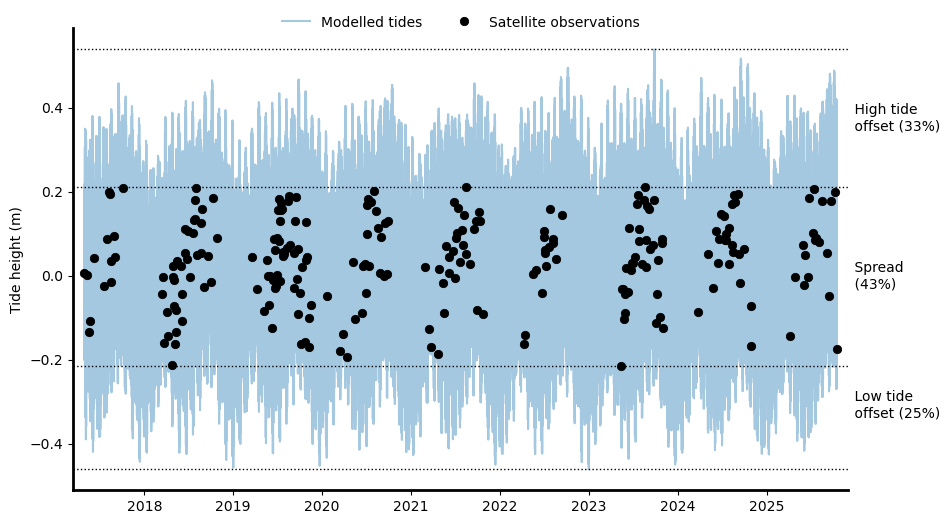

In [7]:
stats = tide_stats(
    data=data_tide_masked,
    model=model,
    directory=tide_data_location,
)

### Identify land and water

We use a water index, here it's a combination of the normalised difference wetness index, NDWI,
and the modified version of that, MNDWI. We find the average of the two indices, which has been
found to be more robust to issues of noisy data over ocean in Sentinel-2.

In [6]:
wi = "combined" #choose one either combined or mndwi_nir

grouped_by_year = water_index(wi,data_tide_masked)

Load into memory for speeding up process

In [7]:
grouped_by_year = grouped_by_year.compute()

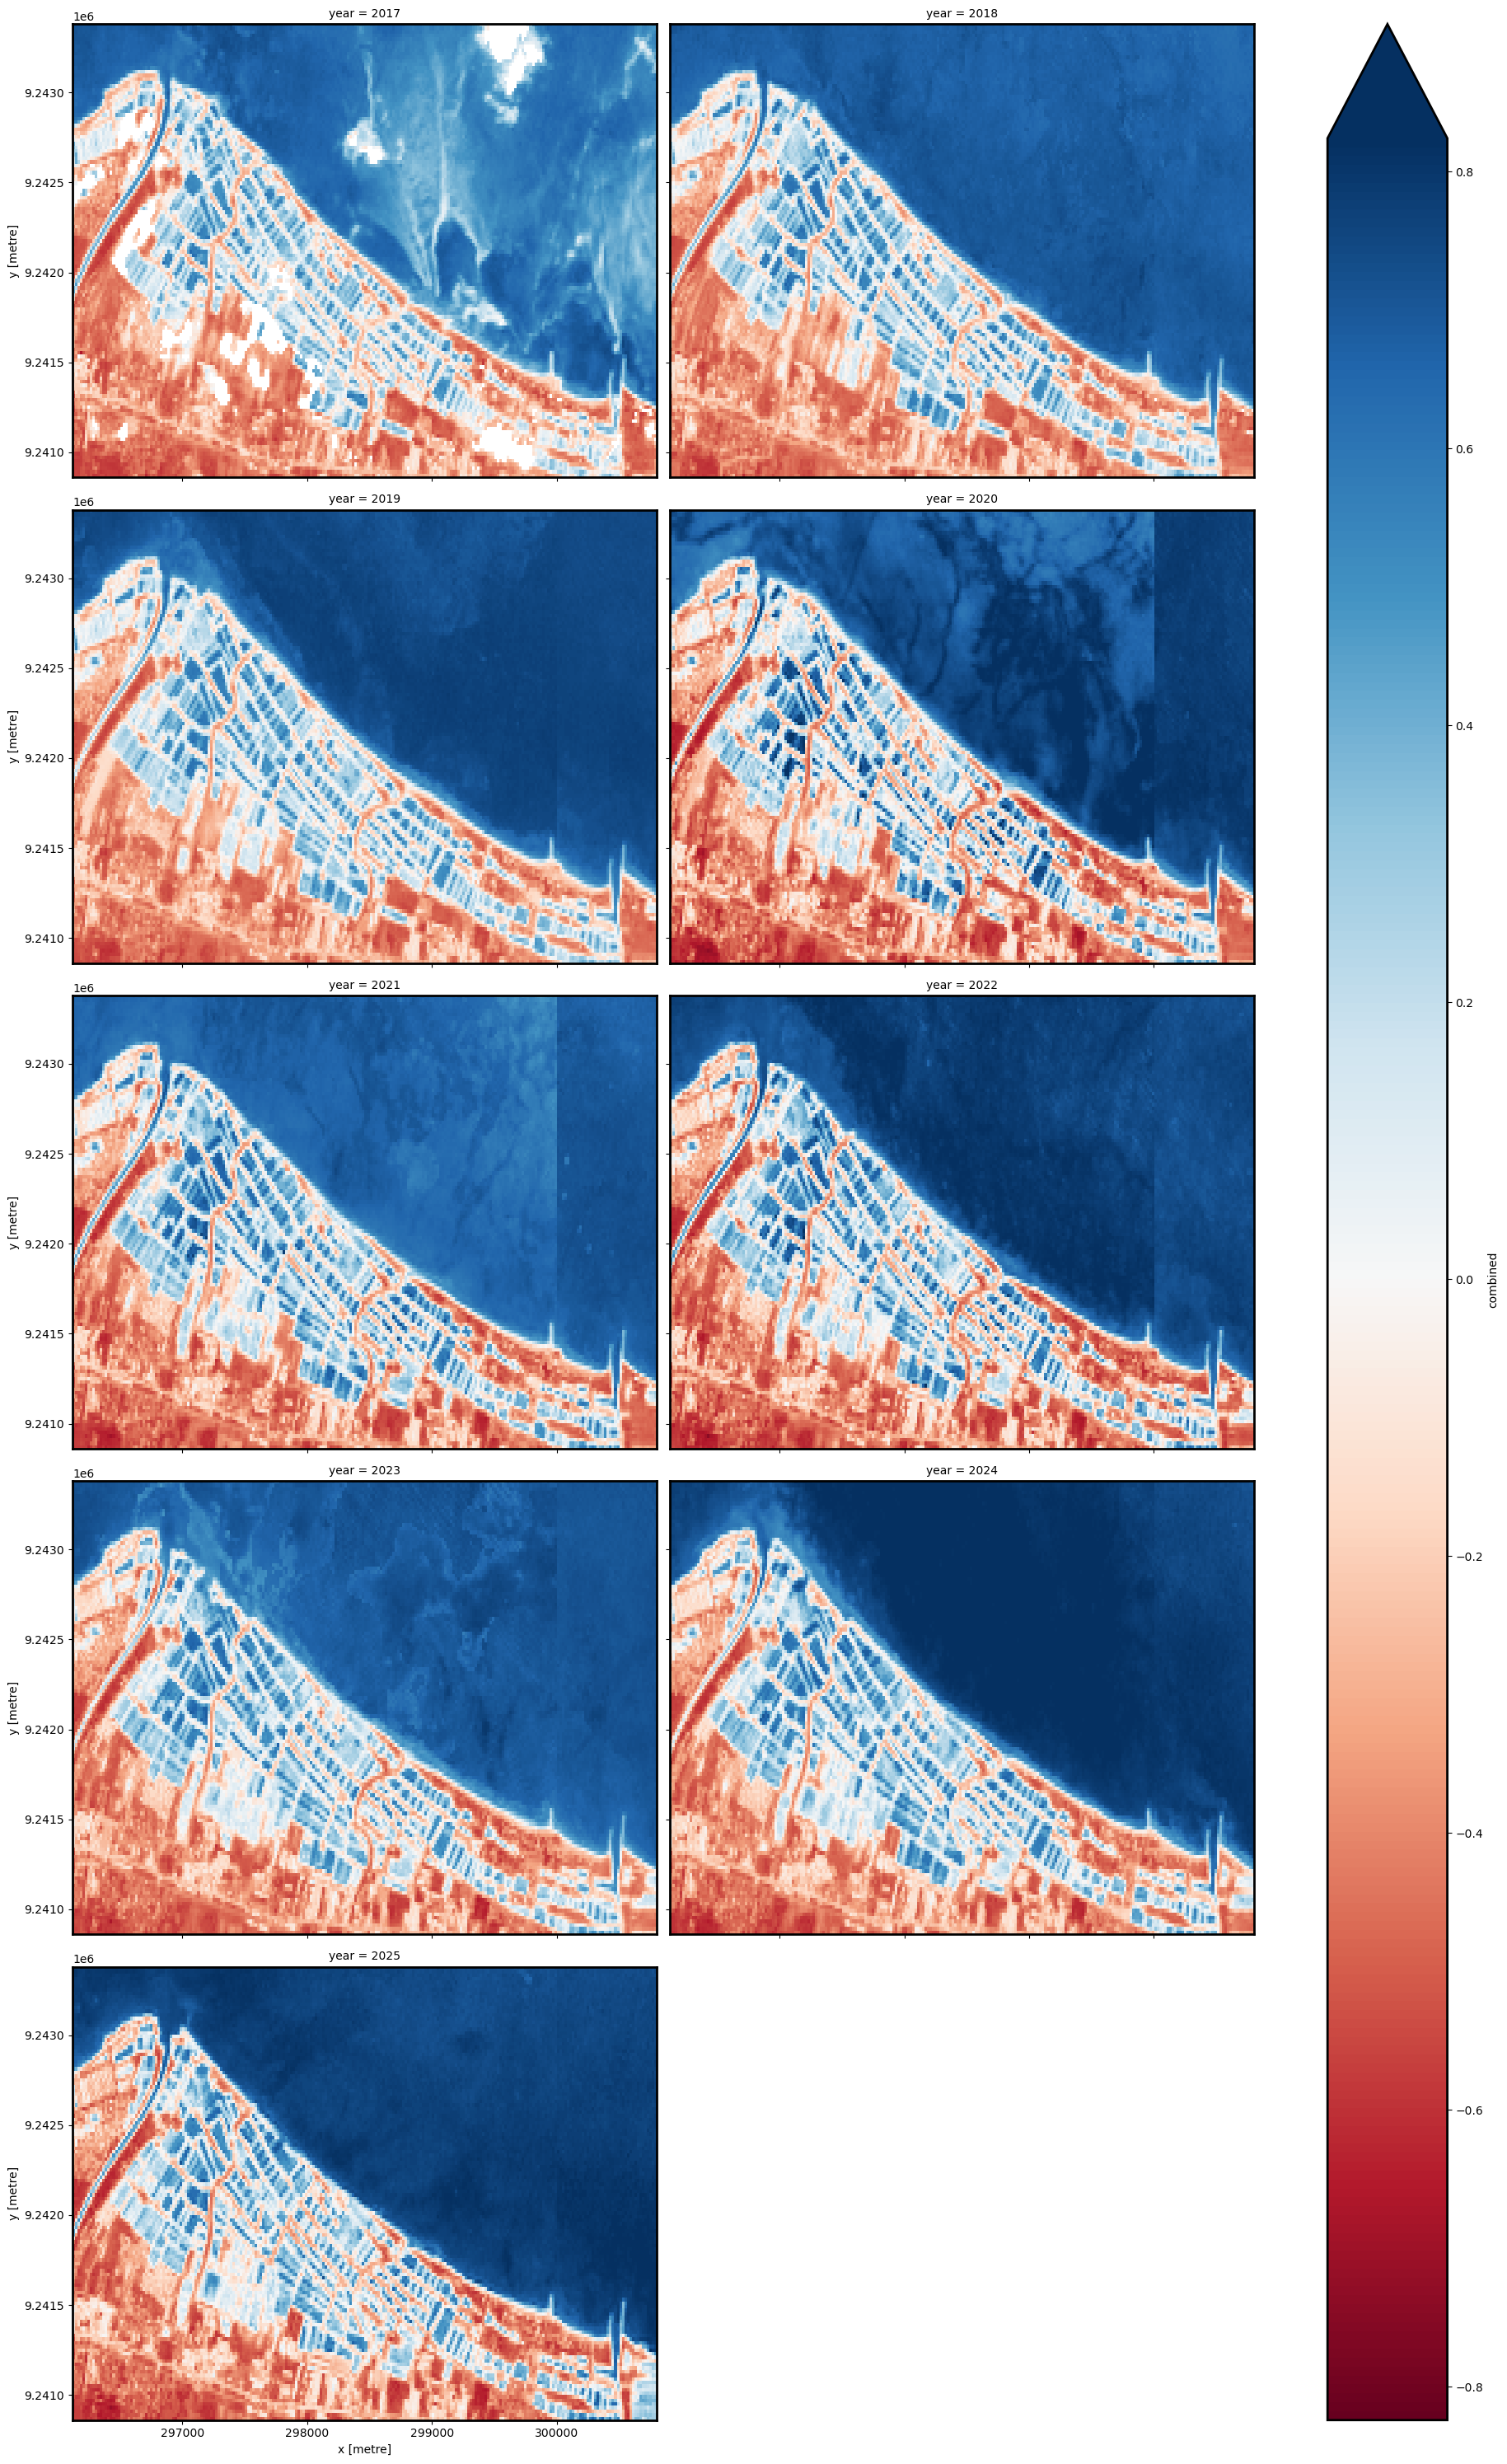

In [8]:
grouped_by_year[wi].plot.imshow(
    col="year", col_wrap=2, size=6, cmap="RdBu", robust=True, aspect=1.5
)

### Coastal Masking

Masking inland water bodies such as fish pond, lake, and channel

In [54]:
coastal_da, masked_ds = inland_water_mask(
    grouped_by_year[wi],
    threshold=0.3,
    min_area=2000,
    dilation_iter=5,
    fill_value=-1,
    wi=wi
)

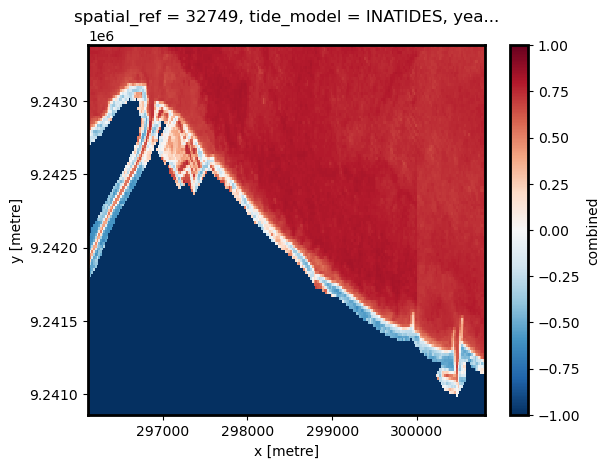

In [55]:
masked_ds[wi].sel(year=2022).plot()

### Extract contours

Next we extract contour lines from the underlying land/water raster data.

In [56]:
# You can also try using the other index above
# use z_value of 0.0 for 'combined'
# use z_value of 0.65 for `mndwi_nir`

z_values = 0

contour_gdf = extract_contours(
    masked_ds, z_values=z_values, index_name=wi
)

contour_gdf.reset_index().explore(
    column="year",
    cmap="magma",
    style_kwds={"weight": 3},
    tiles=basemaps.Esri.WorldImagery,
)


In [13]:
# You can also try using the other index above
# use z_value of 0.0 for 'combined'
# use z_value of 0.65 for `mndwi_nir`

z_values = 0

contour_gdf = extract_contours(
    grouped_by_year, z_values=z_values, index_name=wi
)

contour_gdf.reset_index().explore(
    column="year",
    cmap="magma",
    style_kwds={"weight": 3},
    tiles=basemaps.Esri.WorldImagery,
)


### Extract points

And from the contours, we extract points, and annotate them with change over time, so that
we can document how much the coastline has eroded or accreted.

In [17]:
# Extract points at every 30 metres along the most recent shoreline
points_gdf = points_on_line(contour_gdf, index=2024, distance=30)

# Calculate annual movements based on the points from above
points_gdf = annual_movements(
    points_gdf,
    contours_gdf=contour_gdf,
    yearly_ds=grouped_by_year,
    baseline_year=2024,
    water_index=wi,
)

# And regression lines
points_gdf = calculate_regressions(points_gdf=points_gdf)

## Visualisation

Finally, visualise the results together.

In [18]:
# Add human-friendly label for plotting
points_gdf["Coastal change"] = points_gdf.apply(
    lambda x: f"<h4>This coastline has {'<b>retreated</b>' if x.rate_time < 0 else '<b>grown</b>'} "
    f"by</br><b>{x.rate_time:.2f} m (±{x.se_time:.1f}) per year</b> since "
    f"<b>{contour_gdf.index[0]}</b></h4>",
    axis=1,
)
points_gdf.loc[points_gdf.sig_time > 0.05, "Coastal change"] = (
    f"<h4>No significant trend of retreat or growth)</h4>"
)

m = contour_gdf.reset_index().explore(
    column="year",
    cmap="inferno",
    tooltip=False,
    style_kwds={"opacity": 0.5},
    categorical=True,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="ESRI WorldImagery",
)

points_gdf.explore(
    m=m,
    column="rate_time",
    cmap="RdBu",
    markersize=5,
    tooltip="Coastal change",
)

In [19]:
# Export results to GeoPackage
location = "bali"
points_gdf.to_file(f"{location}_rate_of_change.gpkg", layer="rate_of_change", driver="GPKG")
contour_gdf.to_file(f"{location}_shorlines.gpkg", layer="shorelines", driver="GPKG")